# Week 3, Recap of Week 2 and Matchup Predictions

Two parts. **Part 1** grades the Week 2 predictions against what happened.
**Part 2** makes the Week 3 predictions as weekly totals, same method as Week 2.

**Late start.** Week 3 predictions were made Tuesday Oct 13, after Monday's games
(Canadian Thanksgiving). The window is **Tue Oct 13 to Sun Oct 18**, Monday excluded,
so this is not a full Yahoo week. `predictions/week03.csv` carries `window_start`,
`window_end` and `late_start` columns, and the Week 3 recap should score the same
Tuesday-to-Sunday window.

In [ ]:
!rm -f data_pull.py data_pull.py.* scoring.py scoring.py.* stats.py stats.py.* matchup.py matchup.py.*
!wget -q -O data_pull.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/data_pull.py
!wget -q -O scoring.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/scoring.py
!wget -q -O stats.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/stats.py
!wget -q -O matchup.py https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/src/matchup.py

!mkdir -p predictions
!wget -q -O predictions/week02.csv https://raw.githubusercontent.com/avieno33/fantasy-hockey-weekly-predictions/main/predictions/week02.csv

from data_pull import get_player_id, get_game_log, get_games_in_window #type: ignore
from scoring import SKATER_FIELD_MAP, GOALIE_FIELD_MAP #type: ignore
from stats import get_player_estimates, get_prior_season_stats, _scored_game_log #type: ignore
from matchup import compare_players, compare_weekly #type: ignore

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [ ]:
SEASON = "20262027"
PRIOR_SEASON = "20252026"

# Week 2 (being graded): full Monday to Sunday
WEEK2 = {lg: ("2026-10-05", "2026-10-11") for lg in ("league_1", "league_2", "league_3")}

# Week 3 (being predicted): LATE START, Monday Oct 12 games already played, so Tuesday to Sunday only
WEEK3 = {lg: ("2026-10-13", "2026-10-18") for lg in ("league_1", "league_2", "league_3")}

league_scoring = {
    "league_1": {
        "skater": {"G": 2, "A": 1, "PIM": -0.25, "PPG": 0.5, "SHG": 2, "SHA": 1, "GWG": 1, "SOG": 0.1, "HIT": 0.25, "BLK": 0.25},
        "goalie": {"W": 5, "GA": -1, "SV": 0.1, "SHO": 5},
    },
    "league_2": {
        "skater": {"G": 2.5, "A": 1.5, "PIM": -0.25, "PPG": 0.5, "PPA": 0.25, "SHG": 1, "SHA": 0.5, "GWG": 1, "SOG": 0.1, "HIT": 0.4, "BLK": 0.5},
        "goalie": {"W": 5, "GA": -1, "SV": 0.15, "SHO": 5},
    },
    "league_3": {
        "skater": {"G": 2.55, "A": 2.37, "PPP": 1.77, "SHP": 1.73, "GWG": 3.0, "SOG": 0.1, "HIT": 0.2, "BLK": 0.15},
        "goalie": {"W": 3.85, "GA": -0.05, "SV": 0.03, "SHO": 5.75},
    },
}

SLEEPERS_W2 = ["Paul Cotter", "Eli Tolvanen", "Tommy Novak"]

_id_cache = {}
def resolve_id(player):
    if isinstance(player, (int, np.integer)):
        return int(player)
    if player not in _id_cache:
        _id_cache[player] = get_player_id(player)
    return _id_cache[player]

def cfg_and_map(league, position):
    side = "goalie" if position == "G" else "skater"
    return league_scoring[league][side], (GOALIE_FIELD_MAP if position == "G" else SKATER_FIELD_MAP)

In [ ]:
w2 = pd.read_csv("predictions/week02.csv")
print(w2.shape)
print(w2["league"].value_counts().to_dict())
print(w2["prediction_unit"].unique(), w2["headline_pick"].notna().sum(), "headline picks")

(45, 27)
{'league_3': 18, 'league_2': 14, 'league_1': 13}
['weekly_total' nan] 3 headline picks


In [ ]:
def window_stats(player, position, league, start, end):
    """Games, total and per-game average fantasy points for one player in a date window, under one league's scoring."""
    pid = resolve_id(player)
    cfg, fmap = cfg_and_map(league, position)
    log = _scored_game_log(pid, SEASON, position, cfg, fmap, force_refresh=True)
    if log is None:
        return {"games": 0, "total": 0.0}
    d = log[(log["gameDate"] >= pd.Timestamp(start)) & (log["gameDate"] <= pd.Timestamp(end))]
    return {"games": len(d), "total": float(d["fantasy_points"].sum())}

def outcome(a, b):
    return 1.0 if a > b else (0.0 if a < b else 0.5)

week2 = pd.read_csv("predictions/week02.csv")
week2_scored = week2[week2["p_me_outperforms"].notna()].copy()

rows = []
for _, r in week2_scored.iterrows():
    start, end = WEEK2[r["league"]]
    me = window_stats(r["me"], r["position"], r["league"], start, end)
    opp = window_stats(r["opponent"], r["position"], r["league"], start, end)
    rows.append({**r.to_dict(),
                 "me_games_actual": me["games"], "opp_games_actual": opp["games"],
                 "me_total": me["total"], "opp_total": opp["total"],
                 "result": outcome(me["total"], opp["total"])})

recap2 = pd.DataFrame(rows)
fav_me = recap2["favored"] == "me"
recap2["pick_won"] = np.where(fav_me, recap2["result"], 1 - recap2["result"])
recap2["brier"] = (recap2["p_me_outperforms"] - recap2["result"]) ** 2
recap2["confidence"] = np.maximum(recap2["p_me_outperforms"], 1 - recap2["p_me_outperforms"])

recap2.to_csv("predictions/week02_results.csv", index=False)
print(f"Scored {len(recap2)} Week 2 matchups")
print("Games predicted vs actual (mismatches):")
mm = recap2[(recap2["me_games"] != recap2["me_games_actual"]) | (recap2["opp_games"] != recap2["opp_games_actual"])]
print(mm[["league", "me", "opponent", "me_games", "me_games_actual", "opp_games", "opp_games_actual"]].to_string(index=False) if len(mm) else "none, all game counts matched")

Matched 'Connor McDavid' to 'Connor McDavid'
Pulling fresh game log for 8478402, 20262027
Matched 'Mark Scheifele' to 'Mark Scheifele'
Pulling fresh game log for 8476460, 20262027
Matched 'Tim Stutzle' to 'Tim Stützle'
Pulling fresh game log for 8482116, 20262027
Matched 'Nick Suzuki' to 'Nick Suzuki'
Pulling fresh game log for 8480018, 20262027
Matched 'Filip Forsberg' to 'Filip Forsberg'
Pulling fresh game log for 8476887, 20262027
Matched 'Dylan Guenther' to 'Dylan Guenther'
Pulling fresh game log for 8482699, 20262027
Matched 'Kyle Connor' to 'Kyle Connor'
Pulling fresh game log for 8478398, 20262027
Matched 'Will Smith' to 'Will Smith'
Pulling fresh game log for 8484227, 20262027
Matched 'Brad Marchand' to 'Brad Marchand'
Pulling fresh game log for 8473419, 20262027
Matched 'Ivan Demidov' to 'Ivan Demidov'
Pulling fresh game log for 8484984, 20262027
Matched 'Alex Tuch' to 'Alex Tuch'
Pulling fresh game log for 8477949, 20262027
Matched 'Kirill Marchenko' to 'Kirill Marchenko'
Pul

In [ ]:
n = len(recap2)
print(f"Picks won: {recap2['pick_won'].sum():.1f} of {n} ({recap2['pick_won'].mean():.1%}), Brier {recap2['brier'].mean():.3f}")
print("Brier reference: 0.250 = always 50%.\n")

print("By league:")
print(recap2.groupby("league").agg(n=("pick_won","size"), won=("pick_won","sum"),
      hit_rate=("pick_won","mean"), brier=("brier","mean")).to_string(float_format=lambda v: f"{v:.3f}"))

recap2["bucket10"] = pd.cut(recap2["confidence"], [0.5,0.6,0.7,0.8,1.01], right=False,
                            labels=["50-60%","60-70%","70-80%","80%+"])
print("\nCalibration (10-point buckets):")
print(recap2.groupby("bucket10", observed=False).agg(n=("pick_won","size"), won=("pick_won","sum"),
      avg_conf=("confidence","mean"), hit_rate=("pick_won","mean")).to_string(float_format=lambda v: f"{v:.3f}"))

# Does the game-count edge show up? Unequal-games matchups vs equal
uneq = recap2["me_games_actual"] != recap2["opp_games_actual"]
print("\nEqual games:  ", f"{recap2[~uneq]['pick_won'].sum():.1f} of {(~uneq).sum()}")
print("Unequal games:", f"{recap2[uneq]['pick_won'].sum():.1f} of {uneq.sum()}")

Picks won: 26.0 of 44 (59.1%), Brier 0.244
Brier reference: 0.250 = always 50%.

By league:
           n    won  hit_rate  brier
league                              
league_1  13  7.000     0.538  0.251
league_2  13  8.000     0.615  0.216
league_3  18 11.000     0.611  0.260

Calibration (10-point buckets):
           n    won  avg_conf  hit_rate
bucket10                               
50-60%    15  8.000     0.538     0.533
60-70%    18 11.000     0.652     0.611
70-80%     7  4.000     0.751     0.571
80%+       4  3.000     0.859     0.750

Equal games:   13.0 of 27
Unequal games: 13.0 of 17


In [ ]:
cols = ["league","position","me","opponent","confidence","me_games_actual","opp_games_actual","me_total","opp_total","pick_won"]
print("Headline picks:")
print(recap2[recap2["headline_pick"].notna()].sort_values("headline_pick")[cols].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

print("\nGoalie slots (expected games = games x start share, vs actual games played):")
g = recap2[recap2["position"] == "G"].copy()
g["me_exp"] = g["me_games"] * g["me_start_share"]
g["opp_exp"] = g["opp_games"] * g["opp_start_share"]
print(g[["league","me","me_exp","me_games_actual","opponent","opp_exp","opp_games_actual","me_total","opp_total","pick_won"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

print("\nBiggest misses (largest Brier):")
print(recap2.sort_values("brier", ascending=False).head(5)[["league","position","me","opponent","p_me_outperforms","me_total","opp_total","me_games_actual","opp_games_actual"]].to_string(index=False, float_format=lambda v: f"{v:.2f}"))

Headline picks:
  league position               me       opponent  confidence  me_games_actual  opp_games_actual  me_total  opp_total  pick_won
league_2        C Nathan MacKinnon    Roope Hintz        0.88                3                 3     12.10       8.60      1.00
league_3        C   Connor McDavid  Nico Hischier        0.82                2                 2     12.88      13.68      0.00
league_1        G   Jeremy Swayman Spencer Knight        0.72                3                 2     11.00       3.90      1.00

Goalie slots (expected games = games x start share, vs actual games played):
  league                  me  me_exp  me_games_actual         opponent  opp_exp  opp_games_actual  me_total  opp_total  pick_won
league_1      Jeremy Swayman    1.98                3   Spencer Knight     2.01                 2     11.00       3.90      1.00
league_1      Jake Oettinger    1.98                3       Joel Hofer     1.57                 2     24.90      -0.90      0.00
league_

In [ ]:
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#a8a69f", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

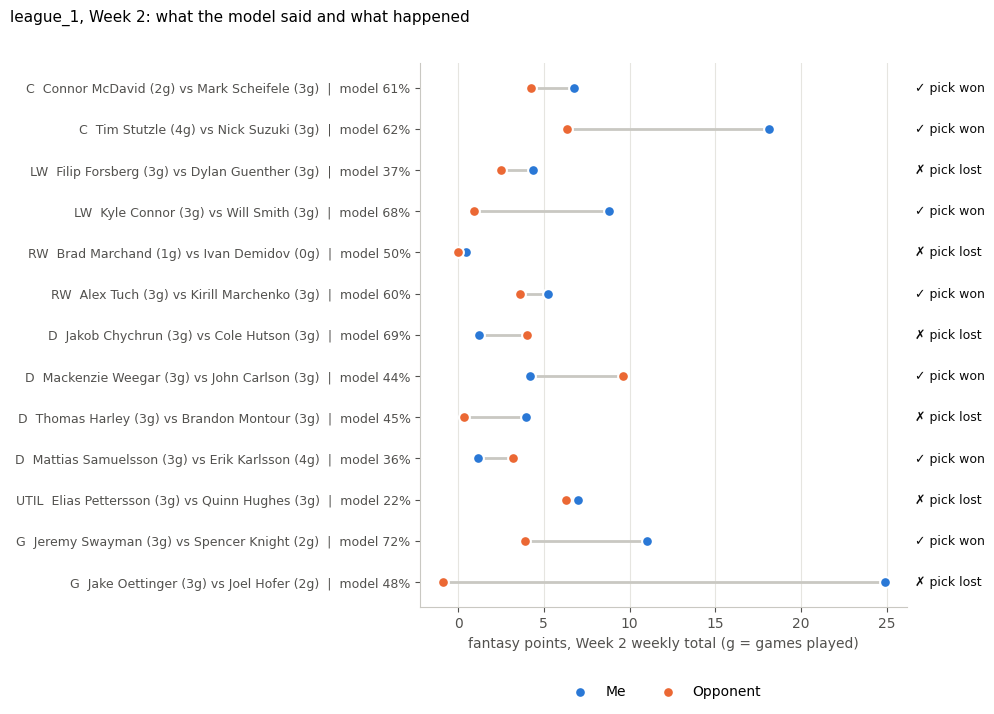

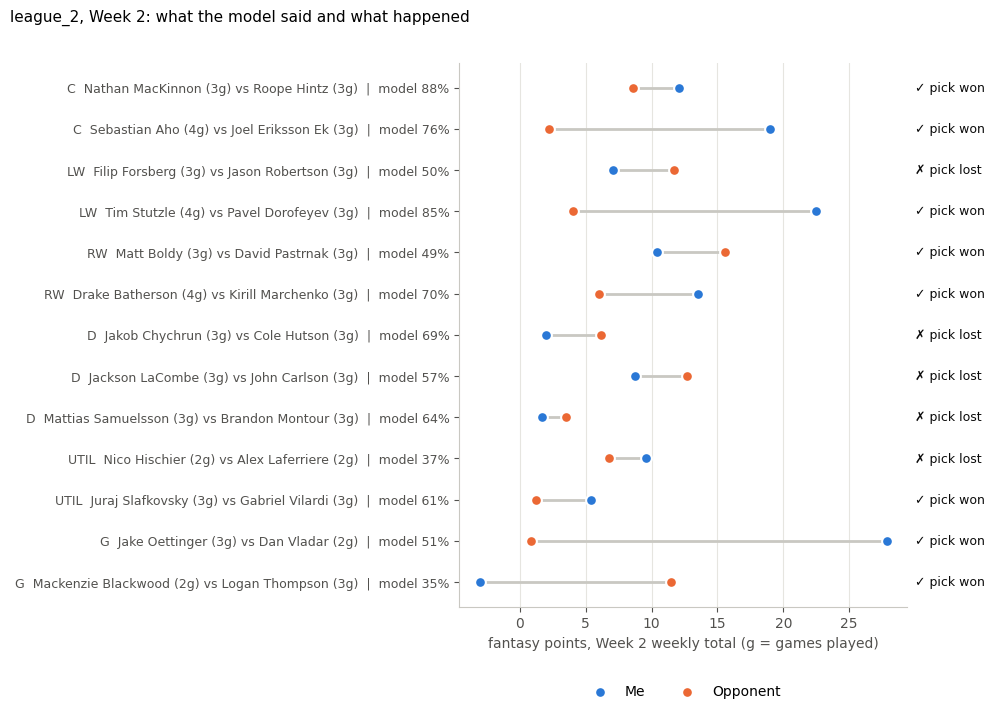

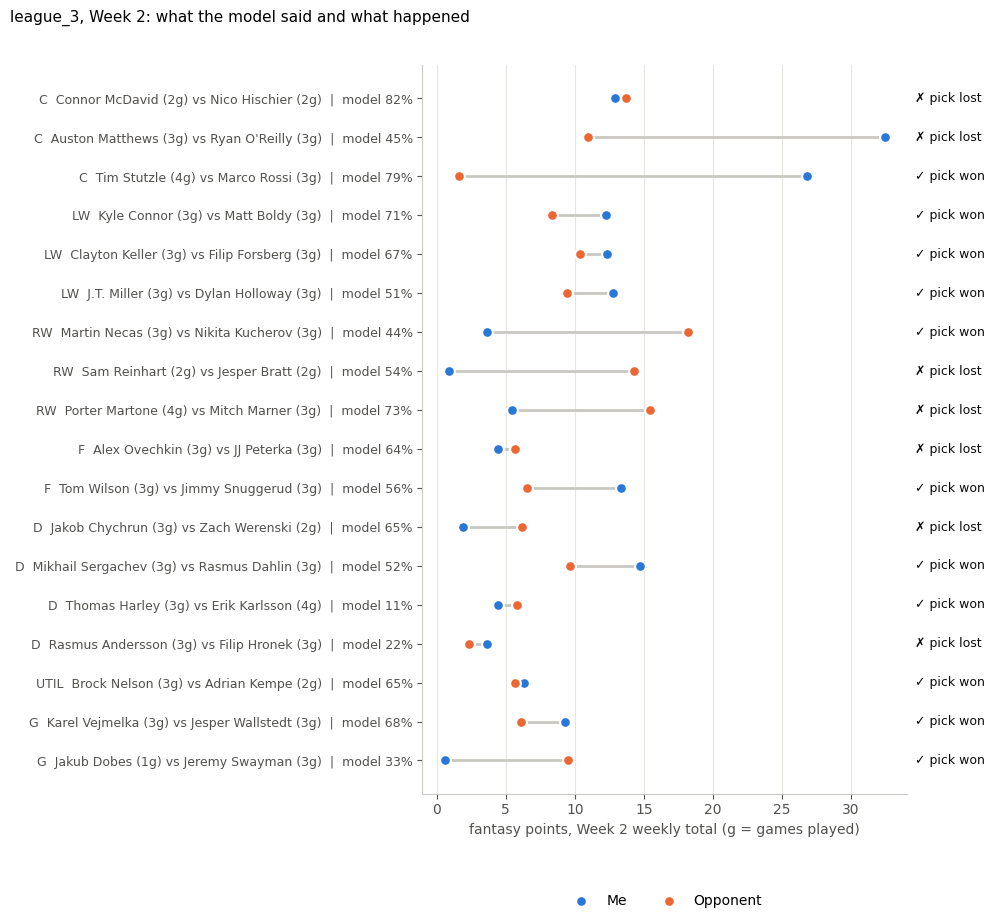

In [ ]:
def plot_week2_matchups(league):
    d = recap2[recap2["league"] == league].reset_index(drop=True)
    y = np.arange(len(d))[::-1]
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(d) + 1.8))
    for yi, r in zip(y, d.itertuples()):
        ax.plot([r.me_total, r.opp_total], [yi, yi], color="#c9c8c2", linewidth=2, zorder=1)
    ax.scatter(d["me_total"], y, s=60, color=BLUE, zorder=3, label="Me", edgecolor="white", linewidth=1.5)
    ax.scatter(d["opp_total"], y, s=60, color=ORANGE, zorder=3, label="Opponent", edgecolor="white", linewidth=1.5)
    labels = [f"{r.position}  {r.me} ({r.me_games_actual}g) vs {r.opponent} ({r.opp_games_actual}g)  |  model {r.p_me_outperforms:.0%}"
              for r in d.itertuples()]
    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=9)
    right = ax.get_xlim()[1]
    for yi, r in zip(y, d.itertuples()):
        sym, txt = ("✓", "pick won") if r.pick_won == 1 else (("=", "tie") if r.pick_won == 0.5 else ("✗", "pick lost"))
        ax.text(right, yi, f"  {sym} {txt}", va="center", fontsize=9, color=INK, clip_on=False)
    ax.set_xlabel("fantasy points, Week 2 weekly total (g = games played)")
    fig.suptitle(f"{league}, Week 2: what the model said and what happened", x=0.01, ha="left", fontsize=11)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, ncol=2)
    ax.grid(axis="y", visible=False)
    plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

for lg in sorted(recap2["league"].unique()):
    plot_week2_matchups(lg)

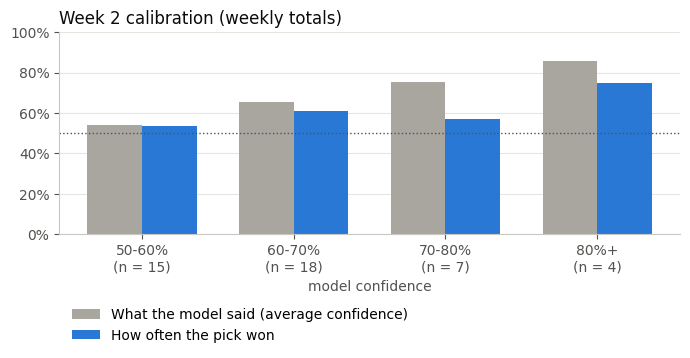

In [ ]:
cal = recap2.groupby("bucket10", observed=False).agg(n=("pick_won","size"),
      avg_conf=("confidence","mean"), hit=("pick_won","mean")).reset_index()
cal = cal[cal["n"] > 0]
x = np.arange(len(cal)); w = 0.36
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - w/2, cal["avg_conf"], w, color=GRAY, label="What the model said (average confidence)")
ax.bar(x + w/2, cal["hit"], w, color=BLUE, label="How often the pick won")
ax.axhline(0.5, color=MUTED, linewidth=1, linestyle=":")
ax.set_xticks(x); ax.set_xticklabels([f"{b}\n(n = {n})" for b, n in zip(cal["bucket10"].astype(str), cal["n"])])
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("model confidence"); ax.set_title("Week 2 calibration (weekly totals)", loc="left")
ax.legend(loc="upper left", frameon=False, bbox_to_anchor=(0, -0.3))
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

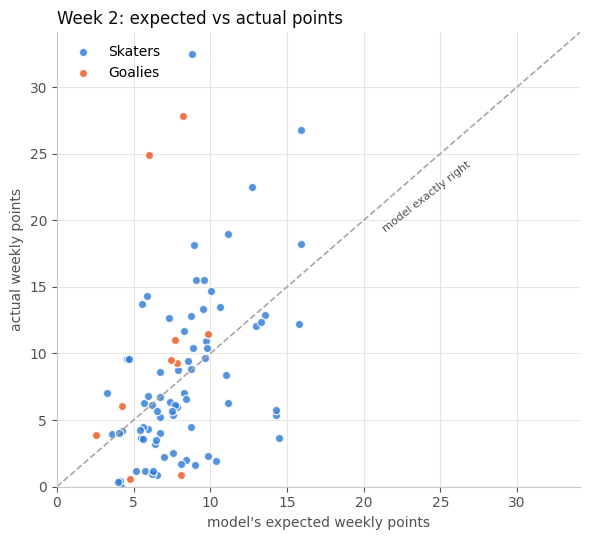

Mean expected 8.00 vs mean actual 8.03


In [ ]:
pts = pd.concat([
    recap2[["position","me","me_week_mu","me_total"]].set_axis(["position","player","pred","actual"], axis=1),
    recap2[["position","opponent","opp_week_mu","opp_total"]].set_axis(["position","player","pred","actual"], axis=1),
])
fig, ax = plt.subplots(figsize=(6, 5.5))
sk, gl = pts[pts["position"] != "G"], pts[pts["position"] == "G"]
ax.scatter(sk["pred"], sk["actual"], s=36, color=BLUE, alpha=0.8, edgecolor="white", label="Skaters")
ax.scatter(gl["pred"], gl["actual"], s=36, color=ORANGE, alpha=0.9, edgecolor="white", label="Goalies")
lim = max(pts["pred"].max(), pts["actual"].max()) * 1.05
ax.plot([0, lim], [0, lim], color=GRAY, linewidth=1.2, linestyle="--")
ax.text(lim*0.62, lim*0.56, "model exactly right", color=MUTED, fontsize=8, rotation=38)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("model's expected weekly points"); ax.set_ylabel("actual weekly points")
ax.set_title("Week 2: expected vs actual points", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()
print(f"Mean expected {pts['pred'].mean():.2f} vs mean actual {pts['actual'].mean():.2f}")

In [ ]:
pts["err"] = pts["actual"] - pts["pred"]
print(f"Mean expected {pts['pred'].mean():.2f}, mean actual {pts['actual'].mean():.2f}")
print(f"Correlation expected vs actual: {pts['pred'].corr(pts['actual']):.2f}")
print(pts.groupby(pts['position'].eq('G').map({True:'Goalies', False:'Skaters'}))["err"].agg(["size","mean"]).round(2))

Mean expected 8.00, mean actual 8.03
Correlation expected vs actual: 0.44
          size  mean
position            
Goalies     12  1.84
Skaters     76 -0.25


In [ ]:
def scoreboard_block_w2():
    n, won = len(recap2), recap2["pick_won"].sum()
    eq = recap2["me_games"] == recap2["opp_games"]
    lines = [
        "**Week 2 results (weekly-total probabilities)**", "",
        f"- All matchups: {won:.1f} of {n} picks won ({won/n:.1%}), Brier {recap2['brier'].mean():.3f}",
        f"- Unequal games: {recap2[~eq]['pick_won'].sum():.1f} of {(~eq).sum()}",
        f"- Equal games: {recap2[eq]['pick_won'].sum():.1f} of {eq.sum()}",
        "", "| Confidence | n | Won | Avg confidence | Hit rate |", "|---|---|---|---|---|",
    ]
    t = recap2.groupby("bucket10", observed=False).agg(n=("pick_won","size"), won=("pick_won","sum"),
            avg=("confidence","mean"), hit=("pick_won","mean"))
    for label, r in t.iterrows():
        if r["n"]:
            lines.append(f"| {label} | {int(r['n'])} | {r['won']:.0f} | {r['avg']:.1%} | {r['hit']:.1%} |")
    lines += ["", "Brier reference: 0.250 = always 50%."]
    return "\n".join(lines)

print(scoreboard_block_w2())

**Week 2 results (weekly-total probabilities)**

- All matchups: 26.0 of 44 picks won (59.1%), Brier 0.244
- Unequal games: 10.0 of 13
- Equal games: 16.0 of 31

| Confidence | n | Won | Avg confidence | Hit rate |
|---|---|---|---|---|
| 50-60% | 15 | 8 | 53.8% | 53.3% |
| 60-70% | 18 | 11 | 65.2% | 61.1% |
| 70-80% | 7 | 4 | 75.1% | 57.1% |
| 80%+ | 4 | 3 | 85.9% | 75.0% |

Brier reference: 0.250 = always 50%.


In [ ]:
sleeper_rows = []
for name in SLEEPERS_W2:
    for league in ("league_1", "league_2", "league_3"):
        start, end = WEEK2[league]
        cfg, fmap = cfg_and_map(league, "F")
        w = window_stats(name, "F", league, start, end)
        prior_mu, _ = get_prior_season_stats(resolve_id(name), PRIOR_SEASON, "F", cfg, fmap)
        avg = w["total"] / w["games"] if w["games"] else np.nan
        sleeper_rows.append({"player": name, "league": league, "week2_games": w["games"], "week2_avg": avg,
                             "last_season_avg": prior_mu,
                             "vs_last_season": (avg / prior_mu - 1) if prior_mu and not pd.isna(avg) else np.nan})
sleepers_w2_recap = pd.DataFrame(sleeper_rows)
print(sleepers_w2_recap.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

Matched 'Paul Cotter' to 'Paul Cotter'
Pulling fresh game log for 8481032, 20262027
Loading game log for 8481032, 20252026 from cache, 1.2 hours old
Pulling fresh game log for 8481032, 20262027
Loading game log for 8481032, 20252026 from cache, 1.2 hours old
Pulling fresh game log for 8481032, 20262027
Loading game log for 8481032, 20252026 from cache, 1.2 hours old
Matched 'Eli Tolvanen' to 'Eeli Tolvanen'
Pulling fresh game log for 8480009, 20262027
Loading game log for 8480009, 20252026 from cache, 1.2 hours old
Pulling fresh game log for 8480009, 20262027
Loading game log for 8480009, 20252026 from cache, 1.2 hours old
Pulling fresh game log for 8480009, 20262027
Loading game log for 8480009, 20252026 from cache, 1.2 hours old
Matched 'Tommy Novak' to 'Tommy Novak'
Pulling fresh game log for 8478438, 20262027
Loading game log for 8478438, 20252026 from cache, 1.2 hours old
Pulling fresh game log for 8478438, 20262027
Loading game log for 8478438, 20252026 from cache, 1.2 hours old


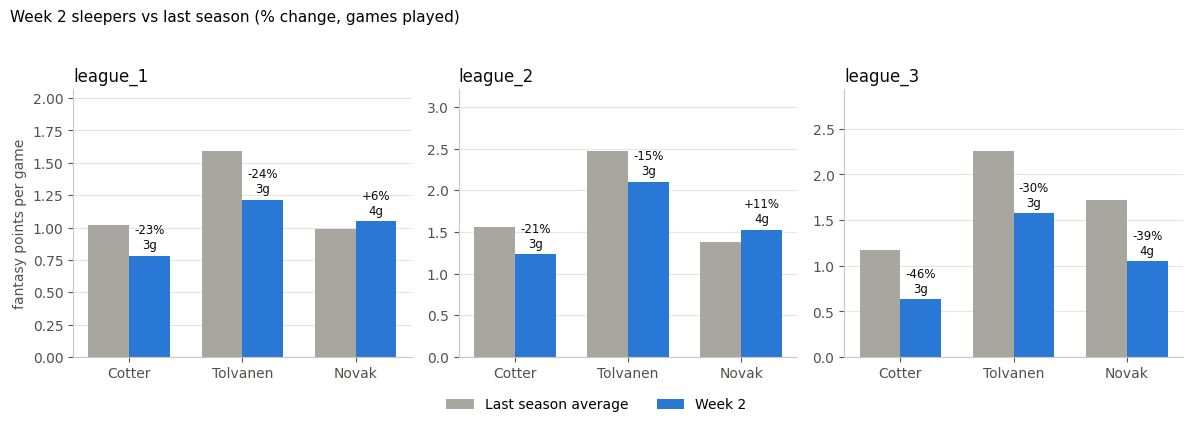

In [ ]:
def plot_sleeper_recap(df):
    leagues = sorted(df["league"].unique())
    players = list(dict.fromkeys(df["player"]))
    fig, axes = plt.subplots(1, len(leagues), figsize=(4.0 * len(leagues), 4.2))
    axes = np.atleast_1d(axes)
    x = np.arange(len(players)); w = 0.36
    for ax, league in zip(axes, leagues):
        d = df[df["league"] == league].set_index("player").loc[players]
        ax.bar(x - w/2, d["last_season_avg"], w, color=GRAY, label="Last season average")
        ax.bar(x + w/2, d["week2_avg"], w, color=BLUE, label="Week 2")
        top = max(d["last_season_avg"].max(), d["week2_avg"].max())
        for xi, (_, r) in zip(x, d.iterrows()):
            ax.text(xi + w/2, r["week2_avg"] + top * 0.02, f"{r['vs_last_season']:+.0%}\n{int(r['week2_games'])}g",
                    ha="center", va="bottom", fontsize=8.5, color=INK)
        ax.set_ylim(0, top * 1.3)
        ax.set_xticks(x); ax.set_xticklabels([p.split()[-1] for p in players])
        ax.set_title(league, loc="left"); ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("fantasy points per game")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, frameon=False)
    fig.suptitle("Week 2 sleepers vs last season (% change, games played)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.06, 1, 0.95)); plt.show()

plot_sleeper_recap(sleepers_w2_recap)

Loading game log for 8481032, 20262027 from cache, 0.0 hours old
Loading game log for 8481032, 20252026 from cache, 1.2 hours old
Loading game log for 8480009, 20262027 from cache, 0.0 hours old
Loading game log for 8480009, 20252026 from cache, 1.2 hours old
Loading game log for 8478438, 20262027 from cache, 0.0 hours old
Loading game log for 8478438, 20252026 from cache, 1.2 hours old


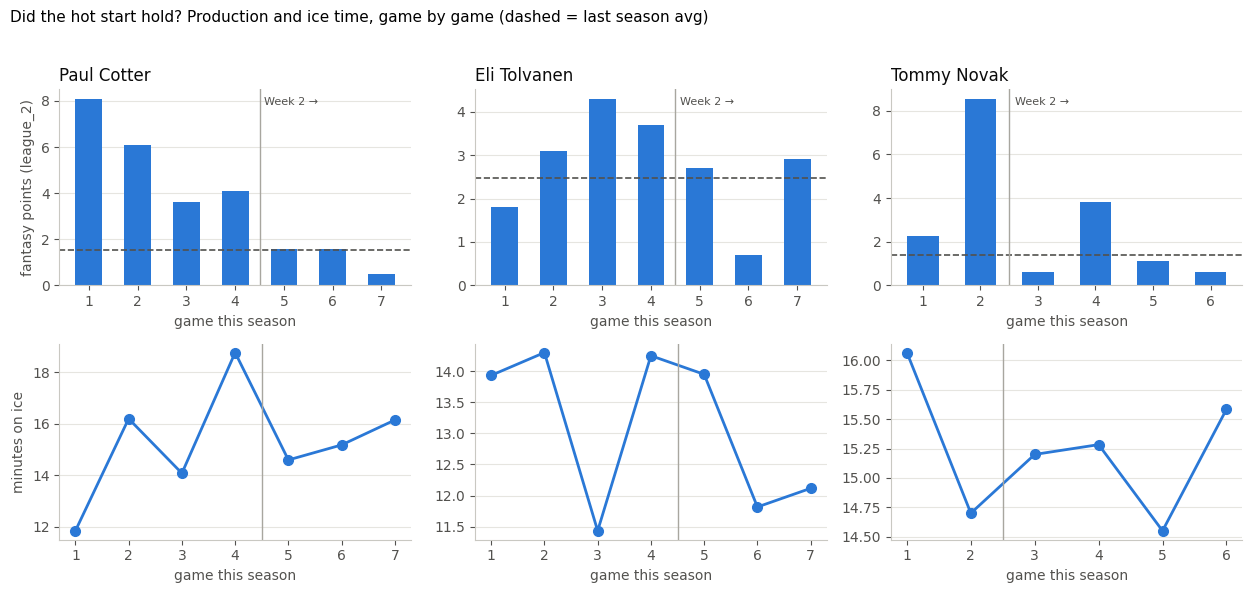

In [ ]:
def toi_minutes(value):
    try:
        m, s = str(value).split(":")
        return int(m) + int(s) / 60
    except Exception:
        return np.nan

def plot_sleeper_games_w2(league="league_2"):
    cfg, fmap = cfg_and_map(league, "F")
    n = len(SLEEPERS_W2)
    fig, axes = plt.subplots(2, n, figsize=(4.2 * n, 6), squeeze=False)
    for j, name in enumerate(SLEEPERS_W2):
        pid = resolve_id(name)
        cur = _scored_game_log(pid, SEASON, "F", cfg, fmap, force_refresh=False)
        last_avg = get_prior_season_stats(pid, PRIOR_SEASON, "F", cfg, fmap)[0]
        ax, ax2 = axes[0, j], axes[1, j]
        if cur is None:
            ax.set_title(f"{name}: no games yet", loc="left"); continue
        cur = cur[cur["gameDate"] <= pd.Timestamp("2026-10-11")].reset_index(drop=True)
        g = np.arange(1, len(cur) + 1)
        split = int((cur["gameDate"] < pd.Timestamp("2026-10-05")).sum()) + 0.5
        ax.bar(g, cur["fantasy_points"], color=BLUE, width=0.55)
        ax.axhline(last_avg, color=MUTED, linestyle="--", linewidth=1.2)
        ax.axvline(split, color=GRAY, linewidth=1)
        ax.text(split + 0.1, ax.get_ylim()[1] * 0.92, "Week 2 →", color=MUTED, fontsize=8)
        ax.set_title(name, loc="left"); ax.set_xticks(g); ax.set_xlabel("game this season")
        if j == 0: ax.set_ylabel(f"fantasy points ({league})")
        ax.grid(axis="x", visible=False)
        if "toi" in cur.columns:
            ax2.plot(g, cur["toi"].map(toi_minutes), color=BLUE, linewidth=2, marker="o", markersize=7)
            ax2.axvline(split, color=GRAY, linewidth=1)
            ax2.set_xticks(g); ax2.set_xlabel("game this season")
            if j == 0: ax2.set_ylabel("minutes on ice")
        ax2.grid(axis="x", visible=False)
    fig.suptitle("Did the hot start hold? Production and ice time, game by game (dashed = last season avg)", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

plot_sleeper_games_w2("league_2")

In [ ]:
from stats import build_full_skater_log  #type: ignore

def process_window(name, season, start=None, end=None):
    log = build_full_skater_log(resolve_id(name), season, include_hits_blocks=False)
    if log.empty:
        return None
    if start is not None:
        d = pd.to_datetime(log["gameDate"])
        log = log[(d >= pd.Timestamp(start)) & (d <= pd.Timestamp(end))]
    if log.empty:
        return None
    shots, goals = log["shots"].sum(), log["goals"].sum()
    return {"games": len(log), "pts_per_game": log["points"].mean(), "shots_per_game": log["shots"].mean(),
            "shooting_pct": goals / shots if shots else np.nan,
            "toi_per_game": log["toi"].map(toi_minutes).mean() if "toi" in log.columns else np.nan}

rows = []
for name in SLEEPERS_W2:
    for label, season, s, e in (("Week 1", SEASON, "2026-09-28", "2026-10-04"),
                                ("Week 2", SEASON, "2026-10-05", "2026-10-11"),
                                ("Last season", PRIOR_SEASON, None, None)):
        r = process_window(name, season, s, e)
        if r:
            rows.append({"player": name, "period": label, **r})
sleepers_process_w2 = pd.DataFrame(rows)
print(sleepers_process_w2.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

Loading game log for 8481032, 20262027 from cache, 0.0 hours old
Loading game log for 8481032, 20262027 from cache, 0.0 hours old
Loading game log for 8481032, 20252026 from cache, 1.2 hours old
Loading game log for 8480009, 20262027 from cache, 0.0 hours old
Loading game log for 8480009, 20262027 from cache, 0.0 hours old
Loading game log for 8480009, 20252026 from cache, 1.2 hours old
Loading game log for 8478438, 20262027 from cache, 0.0 hours old
Loading game log for 8478438, 20262027 from cache, 0.0 hours old
Loading game log for 8478438, 20252026 from cache, 1.2 hours old
      player      period  games  pts_per_game  shots_per_game  shooting_pct  toi_per_game
 Paul Cotter      Week 1      4          1.50            1.75          0.57         15.22
 Paul Cotter      Week 2      3          0.00            0.33          0.00         15.31
 Paul Cotter Last season     79          0.19            0.77          0.15         10.68
Eli Tolvanen      Week 1      4          0.75          

### Week 2 sleepers, did the thesis show up?

Fantasy points per game in Week 2 against last season's per-game average, under each league's scoring:

| Player | Week 2 games | League 1 | League 2 | League 3 |
|---|---|---|---|---|
| Paul Cotter | 3 | -23% | -21% | -46% |
| Eli Tolvanen | 3 | -24% | -15% | -30% |
| Tommy Novak | 4 | +6% | +11% | -39% |

What was underneath it (real NHL points, shots and ice time per game):

| Player | Period | Games | Pts/g | Shots/g | Shooting % | TOI |
|---|---|---|---|---|---|---|
| Cotter | Week 1 | 4 | 1.50 | 1.75 | 57% | 15.2 |
| Cotter | Week 2 | 3 | 0.00 | 0.33 | 0% | 15.3 |
| Cotter | Last season | 79 | 0.19 | 0.77 | 15% | 10.7 |
| Tolvanen | Week 1 | 4 | 0.75 | 1.50 | 50% | 13.5 |
| Tolvanen | Week 2 | 3 | 0.33 | 1.33 | 0% | 12.6 |
| Tolvanen | Last season | 78 | 0.46 | 1.81 | 9% | 16.0 |
| Novak | Week 1 | 2 | 2.00 | 1.50 | 67% | 15.4 |
| Novak | Week 2 | 4 | 0.25 | 1.75 | 14% | 15.1 |
| Novak | Last season | 82 | 0.51 | 1.59 | 12% | 14.3 |

None of the three beat last season's baseline in a convincing way. Cotter and Tolvanen were below it in every league, and Novak was roughly flat in leagues 1 and 2 (his shots, hits and blocks helped) and well down in league 3, which pays mostly for points.

What the process numbers say:
- **Hot shooting percentages did not last.** Cotter's 57% and Novak's 67% in Week 1 became 0% and 14% in Week 2, which is what I flagged going in.
- **Novak behaved like a player whose role was unchanged.** His ice time (15.4 to 15.1 minutes) and shots (1.50 to 1.75 per game) held, and his points fell back to about his baseline. There was never a change in role to be had there.
- **Cotter's ice time held** (15.3 minutes, up from 10.7 last season), but his shots fell from 1.75 to 0.33 per game. That is one shot in three games, so I can't tell a real change from a short slump. The ice-time bump is the part of the thesis that survived.
- **Tolvanen's ice time kept falling** (13.5 to 12.6 minutes, against 16.0 last season) and his shots stayed below last season's level. This was the warning sign in Week 1, and it held.

Three players, 3 to 4 games each in Week 2 (Cotter's whole week is 1 shot), so this is a start to the tracking and not evidence about the method. The question to keep asking is whether sleepers chosen for a shots-and-ice-time change hold up better than ones chosen off a hot shooting percentage.

**What I take from Week 2:**
- 26 of 44 picks won (59.1%), Brier 0.244, a hair better than a coin flip (0.250). One week, so not evidence of skill.
- The wins came mostly where game counts differed (10 of 13). On equal-game matchups the model was 16 of 31 (52%), and across both weeks it is 22 of 44 (50%). The schedule edge is working; separating two similar players is not, yet.
- The weekly point estimates are well centred: mean expected 8.00 vs mean actual 8.03 points per player, correlation 0.44. Skaters came in 0.25 below expectation on average, goalies 1.84 above.
- Calibration: wins landed at or slightly below stated confidence in the upper buckets (70-80%: 4 of 7, 80%+: 3 of 4), within noise at these sample sizes.
- Games missed to injury or scratches (Demidov 0 of 3, Marchand 1 of 2, Dobes 1 of 3) cost several slots. The model assumes everyone plays every team game.
- Goalies: 5 of 6 picks won, but all twelve goalies played 30 games against 22.5 expected from last season's start share, and goalies beat their expected points by 1.84 each. Watching whether early-season usage keeps running above start share over the next few weeks. No model change on one week.

# Part 2, Week 3 Predictions

In [ ]:
matchups_w3 = {
        "league_1": [
        {"position": "C", "me": "Connor McDavid", "opponent": "Nathan Mackinnon"},
        {"position": "C", "me": "Tim Stutzle", "opponent": "Fraser Minten"},
        {"position": "LW", "me": "Filip Forsberg", "opponent": "Pavel Dorofeyev"},
        {"position": "LW", "me": "Kyle Connor", "opponent": "Juraj Slafkovsky"},
        {"position": "RW", "me": "Cole Perfetti", "opponent": "Logan Stankoven"},
        {"position": "RW", "me": "Alex Tuch", "opponent": "Connor Bedard"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Lane Hutson"},
        {"position": "D", "me": "Mackenzie Weegar", "opponent": "Owen Power"},
        {"position": "D", "me": "Noah Dobson", "opponent": "Vladislav Gavrikov"},
        {"position": "D", "me": "Mattias Samuelsson", "opponent": "Jaccob Slavin"},
        {"position": "UTIL", "me": "Elias Pettersson", "opponent": "Artturi Lehkonen"},
        {"position": "G", "me": "Jeremy Swayman", "opponent": "Lukas Dostal"},
        {"position": "G", "me": "Jake Oettinger", "opponent": "Yaroslav Askarov"},
    ],
    "league_2": [
        {"position": "C", "me": "Nathan MacKinnon", "opponent": "Brock Nelson"},
        {"position": "C", "me": "Sebastian Aho", "opponent": "Brayden Point"},
        {"position": "LW", "me": "Filip Forsberg", "opponent": "Brandon Hagel"},
        {"position": "LW", "me": "Tim Stutzle", "opponent": "Rickard Rakell"},
        {"position": "RW", "me": "Matt Boldy", "opponent": "Patrick Kane"},
        {"position": "RW", "me": "Drake Batherson", "opponent": "Mitch Marner"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Rasmus Andersson"},
        {"position": "D", "me": "Jackson LaCombe", "opponent": "Shayne Gostisbehere"},
        {"position": "D", "me": "Mattias Samuelsson", "opponent": "Victor Hedman"},
        {"position": "D", "me": "Charlie McAvoy", "opponent": "Mattias Ekholm"},
        {"position": "UTIL", "me": "Sam Reinhart", "opponent": "Kyle Connor"},
        {"position": "UTIL", "me": "Elias Pettersson", "opponent": "Lawson Crouse"},
        {"position": "G", "me": "Jake Oettinger", "opponent": "Jesper Wallstedt"},
        {"position": "G", "me": "Mackenzie Blackwood", "opponent": "Arturs Silovs"},
    ],

    "league_3": [
        {"position": "C", "me": "Connor McDavid", "opponent": "Nick Suzuki"},
        {"position": "C", "me": "Auston Matthews", "opponent": "Mika Zibanejad"},
        {"position": "C", "me": "Tim Stutzle", "opponent": "Tomas Hertl"},
        {"position": "LW", "me": "Kyle Connor", "opponent": "Alex Debrincat"},
        {"position": "LW", "me": "Clayton Keller", "opponent": "Alex Tuch"},
        {"position": "LW", "me": "J.T. Miller", "opponent": "Leon Draisaitl"},
        {"position": "RW", "me": "Martin Necas", "opponent": "Mark Stone"},
        {"position": "RW", "me": "Sam Reinhart", "opponent": "Vasily Podkolzin"},
        {"position": "RW", "me": "Will Cuylle", "opponent": "Matthew Tkachuk"},
        {"position": "F", "me": "Alex Ovechkin", "opponent": "Sebastian Aho"},
        {"position": "F", "me": "Tom Wilson", "opponent": "William Nylander"},
        {"position": "D", "me": "Jakob Chychrun", "opponent": "Shayne Gostisbehere"},
        {"position": "D", "me": "Mikhail Sergachev", "opponent": "Mackenzie Weegar"},
        {"position": "D", "me": "Thomas Harley", "opponent": "Evan Bouchard"},
        {"position": "D", "me": "Rasmus Andersson", "opponent": "Noah Dobson"},
        {"position": "UTIL", "me": "Brock Nelson", "opponent": "Dylan Larkin"},
        {"position": "G", "me": "Karel Vejmelka", "opponent": "Jet Greaves"},
        {"position": "G", "me": "Jakub Dobes", "opponent": "Brandon Bussi"},
    ],
}

In [ ]:
# Only needed when the automatic team lookup gets someone wrong, name -> NHL team abbreviation
TEAM_OVERRIDES = {
    # "Some Player": "TOR",
}

# Only needed to override the automatic goalie start-share, name -> share of team games he starts (0 to 1)
GOALIE_START_SHARE = {
    # "Jake Oettinger": 0.6,
}

def current_team(player):
    """Most recent team from the game log, this season first, then last season. Returns (team, source)."""
    if player in TEAM_OVERRIDES:
        return TEAM_OVERRIDES[player], "override"
    pid = resolve_id(player)
    for season, source in ((SEASON, "this season"), (PRIOR_SEASON, "last season, VERIFY")):
        log = get_game_log(pid, season=season)
        if not log.empty and "teamAbbrev" in log.columns:
            return log.sort_values("gameDate").iloc[-1]["teamAbbrev"], source
    return None, "not found"

def goalie_start_share(player):
    """Share of his team's games a goalie starts, from last season's starts out of 82, unless overridden."""
    if player in GOALIE_START_SHARE:
        return GOALIE_START_SHARE[player]
    log = get_game_log(resolve_id(player), season=PRIOR_SEASON)
    if log.empty or len(log) < 20 or "gamesStarted" not in log.columns:
        return 0.5
    starts = pd.to_numeric(log["gamesStarted"], errors="coerce").fillna(0).sum()
    return float(min(max(starts / 82, 0.15), 0.95))

def is_placeholder(value):
    return isinstance(value, str) and (value.startswith("None") or "suspended" in value.lower())

def run_weekly_comparisons(league):
    start, end = WEEK3[league]
    results = []
    for m in matchups_w3[league]:
        pos = m["position"]
        base = {"week": 3, "league": league, "position": pos, "me": m["me"], "opponent": m["opponent"]}

        if is_placeholder(m["me"]) or is_placeholder(m["opponent"]):
            results.append({**base, "note": "no real comparison in this slot"})
            continue

        cfg, fmap = cfg_and_map(league, pos)
        me_id, opp_id = resolve_id(m["me"]), resolve_id(m["opponent"])
        me_est = get_player_estimates(me_id, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        opp_est = get_player_estimates(opp_id, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        if me_est is None or opp_est is None:
            results.append({**base, "note": f"skipped (no data: me={me_est is not None}, opp={opp_est is not None})"})
            continue

        me_team, me_src = current_team(m["me"])
        opp_team, opp_src = current_team(m["opponent"])
        if me_team is None or opp_team is None:
            results.append({**base, "note": "skipped (could not find a team, add a TEAM_OVERRIDES entry)"})
            continue

        me_games = len(get_games_in_window(me_team, start, end))
        opp_games = len(get_games_in_window(opp_team, start, end))
        me_share = goalie_start_share(m["me"]) if pos == "G" else 1.0
        opp_share = goalie_start_share(m["opponent"]) if pos == "G" else 1.0

        kwargs = dict(label_a=str(m["me"]), label_b=str(m["opponent"]), start_share_a=me_share, start_share_b=opp_share)
        weekly = compare_weekly(me_est, me_games, opp_est, opp_games, use="season", **kwargs)
        weekly_recent = compare_weekly(me_est, me_games, opp_est, opp_games, use="recent", **kwargs)
        per_game = compare_players(me_est, opp_est, str(m["me"]), str(m["opponent"]))

        p = weekly["probability_a_outperforms_b"]
        notes = []
        if "VERIFY" in me_src or "VERIFY" in opp_src:
            notes.append("team taken from last season, verify")
        if me_games == 0 or opp_games == 0:
            notes.append("a player has no games this week")
        results.append({
            **base,
            "me_team": me_team, "opp_team": opp_team,
            "me_games": me_games, "opp_games": opp_games,
            "me_start_share": me_share if pos == "G" else np.nan,
            "opp_start_share": opp_share if pos == "G" else np.nan,
            "me_week_mu": weekly["mu_a"], "opp_week_mu": weekly["mu_b"],
            "me_week_sigma": weekly["sigma_a"], "opp_week_sigma": weekly["sigma_b"],
            "p_me_outperforms": p,
            "confidence": max(p, 1 - p),
            "favored": "me" if p > 0.5 else ("opponent" if p < 0.5 else "even"),
            "p_per_game": per_game["probability_a_outperforms_b"],
            "p_recent_form": weekly_recent["probability_a_outperforms_b"],
            "me_games_so_far": me_est["games_played"], "opp_games_so_far": opp_est["games_played"],
            "low_confidence": bool(me_est["low_confidence"] or opp_est["low_confidence"]),
            "prediction_unit": "weekly_total",
            "headline_pick": np.nan,
            "note": "; ".join(notes),
        })
    return pd.DataFrame(results)

active = [lg for lg, ms in matchups_w3.items() if ms]
print("Leagues with matchups:", active or "none yet, paste matchups above and re-run")
week3_results = {lg: run_weekly_comparisons(lg) for lg in active}

Leagues with matchups: ['league_1', 'league_2', 'league_3']
Matched 'Nathan Mackinnon' to 'Nathan MacKinnon'
Loading game log for 8478402, 20262027 from cache, 0.0 hours old
Loading game log for 8478402, 20252026 from cache, 1.9 hours old
Loading game log for 8477492, 20262027 from cache, 0.0 hours old
Loading game log for 8477492, 20252026 from cache, 1.8 hours old
Loading game log for 8478402, 20262027 from cache, 0.0 hours old
Loading game log for 8477492, 20262027 from cache, 0.0 hours old
Matched 'Fraser Minten' to 'Fraser Minten'
Loading game log for 8482116, 20262027 from cache, 0.0 hours old
Loading game log for 8482116, 20252026 from cache, 1.8 hours old
Loading game log for 8483489, 20262027 from cache, 1.8 hours old
Loading game log for 8483489, 20252026 from cache, 1.8 hours old
Loading game log for 8482116, 20262027 from cache, 0.0 hours old
Loading game log for 8483489, 20262027 from cache, 1.8 hours old
Loading game log for 8476887, 20262027 from cache, 0.0 hours old
Loa

In [ ]:
allr = pd.concat(week3_results.values())
print(pd.concat([allr["me_games"], allr["opp_games"]]).value_counts().sort_index().rename("players with this many games"))
print(allr[allr["note"].fillna("") != ""][["league","me","opponent","note"]].to_string(index=False))

In [ ]:
print(allr[allr["me"].isin(["Alex Tuch","Charlie McAvoy"]) | allr["opponent"].isin(["Connor Bedard","Mattias Ekholm"])]
      [["league","me","me_team","opponent","opp_team","me_games","opp_games","me_games_so_far","opp_games_so_far","low_confidence"]].to_string(index=False))

In [ ]:
all_w3 = pd.concat(week3_results.values(), ignore_index=True)
show = ["position", "me", "opponent", "me_games", "opp_games", "me_week_mu", "opp_week_mu",
        "p_me_outperforms", "p_per_game", "p_recent_form", "low_confidence", "note"]
for league, df in week3_results.items():
    print(f"\n=== {league.upper()} ===")
    d = df.copy()
    for c in ("p_me_outperforms", "p_per_game", "p_recent_form"):
        if c in d:
            d[c] = d[c].map(lambda p: f"{p:.1%}" if pd.notna(p) else "n/a")
    print(d[[c for c in show if c in d.columns]].to_string(index=False, float_format=lambda v: f"{v:.1f}"))

print()
for league, df in week3_results.items():
    d = df[df["p_me_outperforms"].notna()]
    if d.empty:
        continue
    print(f"{league}: favored in {int((d['favored'] == 'me').sum())} of {len(d)} comparable slots, "
          f"{d['p_me_outperforms'].mean():.1%} average win probability across slots")
    for r in d[(d["p_me_outperforms"] - 0.5).abs() < 0.02].itertuples():
        print(f"   coin flip: {r.me} vs {r.opponent} ({r.p_me_outperforms:.1%})")
    for r in d[d["me_games"] != d["opp_games"]].itertuples():
        print(f"   unequal games: {r.me} {r.me_games:.0f} vs {r.opponent} {r.opp_games:.0f}")
    for r in df[df["p_me_outperforms"].isna()].itertuples():
        print(f"   {r.me} vs {r.opponent}: {r.note}")


=== LEAGUE_1 ===
position                 me           opponent  me_games  opp_games  me_week_mu  opp_week_mu p_me_outperforms p_per_game p_recent_form  low_confidence                                note
       C     Connor McDavid   Nathan Mackinnon         3          3        10.1          9.6            53.5%      52.0%         64.6%           False                                    
       C        Tim Stutzle      Fraser Minten         3          3         8.7          3.9            85.0%      72.5%         91.2%           False                                    
      LW     Filip Forsberg    Pavel Dorofeyev         3          3         5.6          4.7            59.3%      55.4%         66.5%           False                                    
      LW        Kyle Connor   Juraj Slafkovsky         3          3         8.7          5.0            80.1%      68.7%         86.6%           False                                    
      RW      Cole Perfetti    Logan Stankoven 

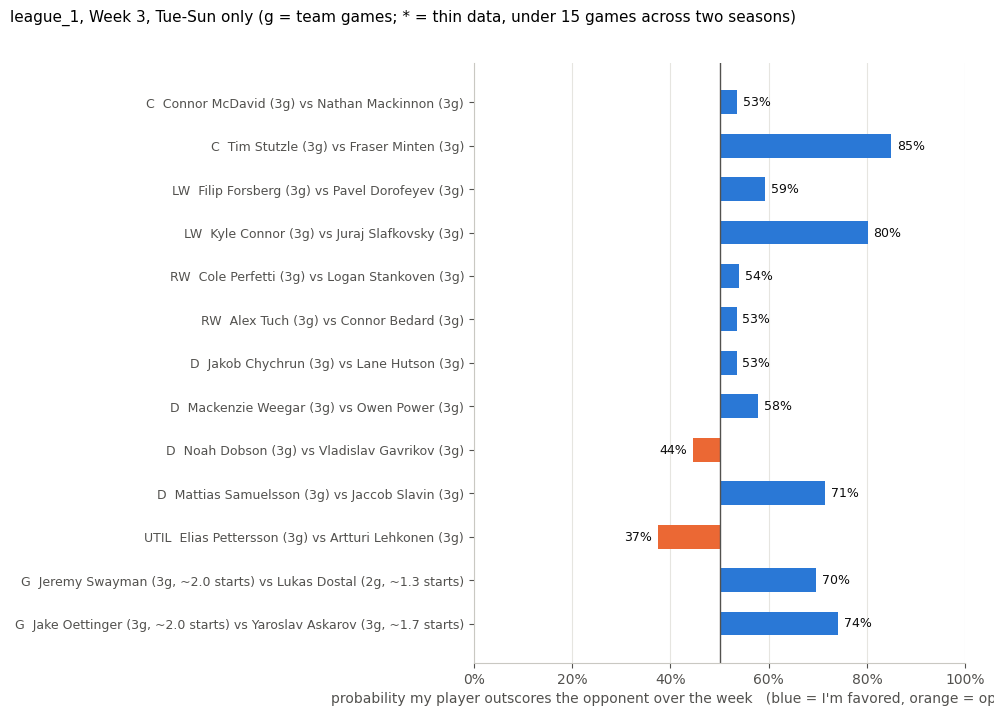

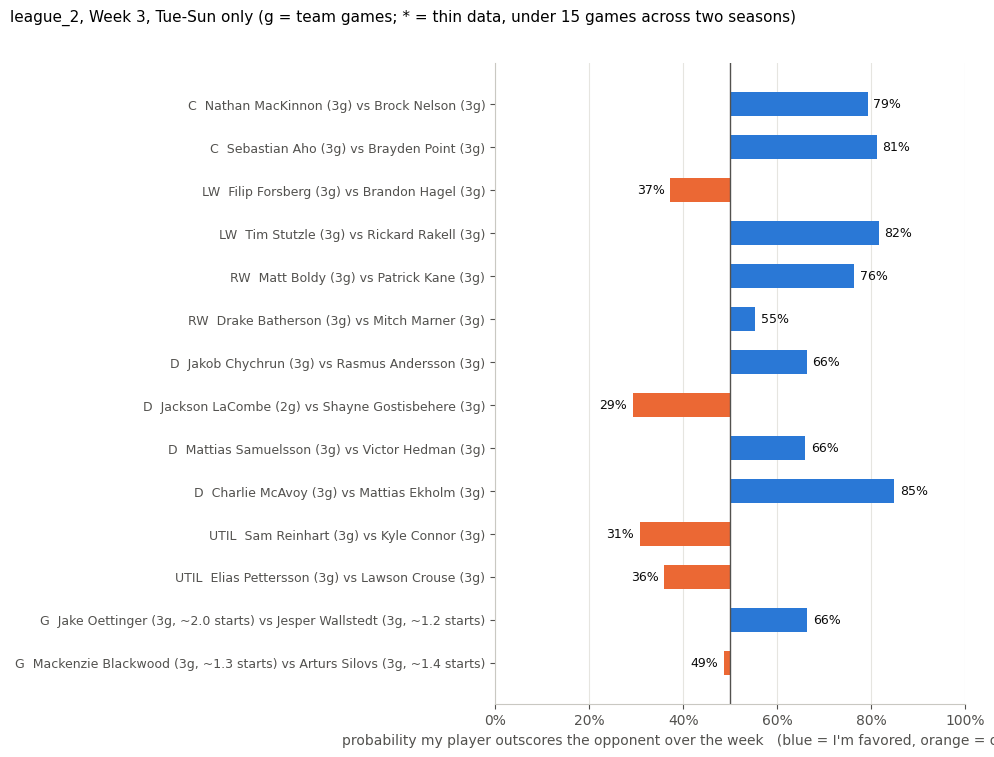

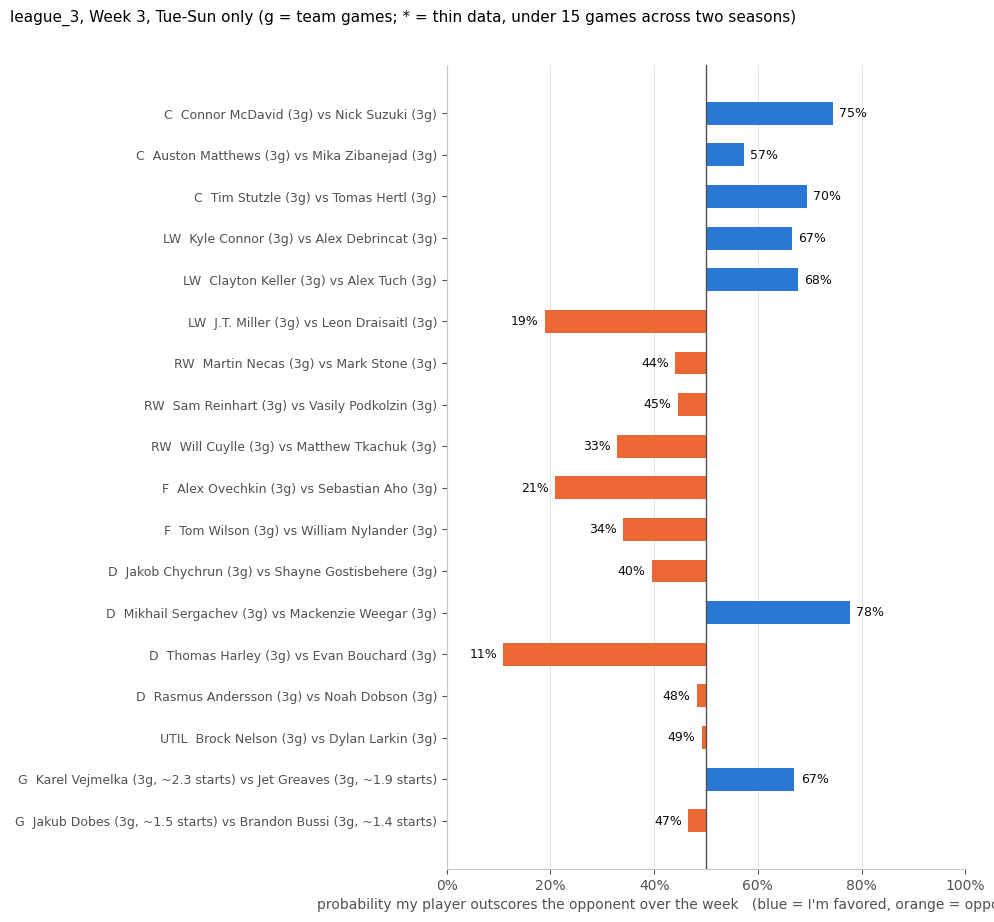

In [ ]:
def plot_week3_bars(league, df):
    d = df[df["p_me_outperforms"].notna()].reset_index(drop=True)
    if d.empty:
        return
    y = np.arange(len(d))[::-1]
    colors = np.where(d["p_me_outperforms"] >= 0.5, BLUE, ORANGE)
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(d) + 1.8))
    ax.barh(y, d["p_me_outperforms"] - 0.5, left=0.5, color=colors, height=0.55)
    ax.axvline(0.5, color=MUTED, linewidth=1)
    star = np.where(d["low_confidence"].astype(bool), " *", "")
    def side(name, games, share):
        return f"{name} ({games:.0f}g)" if pd.isna(share) else f"{name} ({games:.0f}g, ~{games * share:.1f} starts)"
    labels = [f"{r.position}  {side(r.me, r.me_games, r.me_start_share)} vs {side(r.opponent, r.opp_games, r.opp_start_share)}{s}"
              for r, s in zip(d.itertuples(), star)]
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=9)
    for yi, p in zip(y, d["p_me_outperforms"]):
        ax.text(p + (0.012 if p >= 0.5 else -0.012), yi, f"{p:.0%}", va="center",
                ha="left" if p >= 0.5 else "right", fontsize=9, color=INK)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_xlabel("probability my player outscores the opponent over the week   (blue = I'm favored, orange = opponent favored)")
    fig.suptitle(f"{league}, Week 3, Tue-Sun only (g = team games; * = thin data, under 15 games across two seasons)",
                 x=0.01, ha="left", fontsize=11)
    ax.grid(axis="y", visible=False)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()

for league, df in week3_results.items():
    plot_week3_bars(league, df)

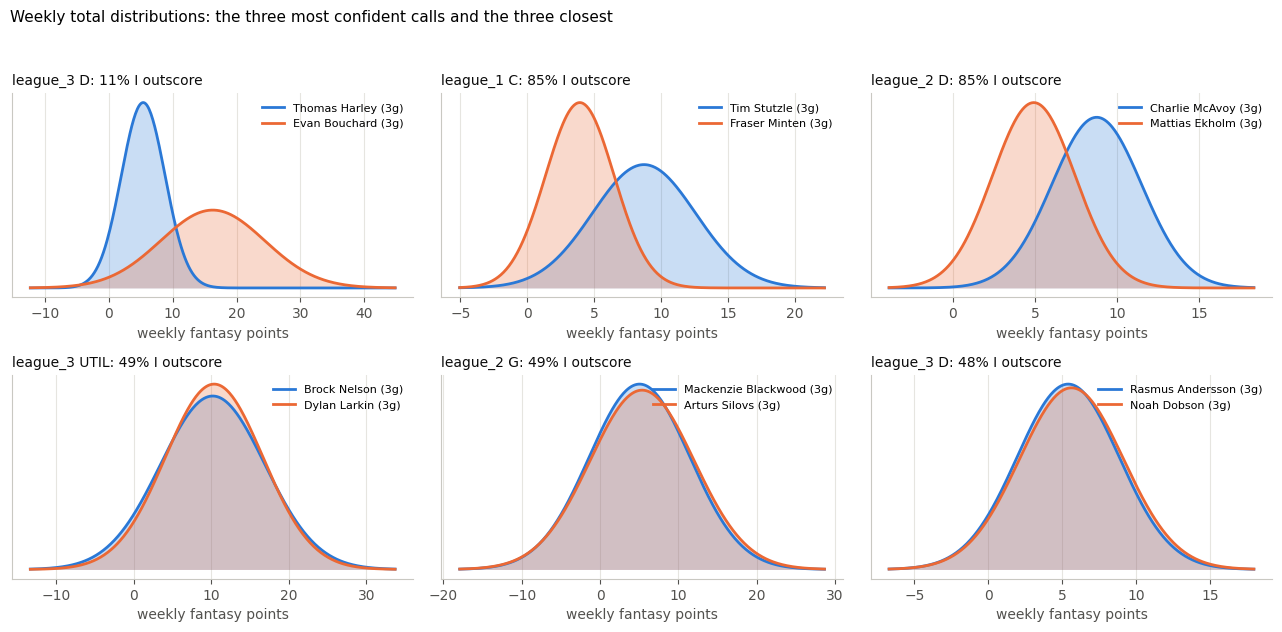

In [ ]:
def plot_week3_distributions(all_df, n_each=3):
    ok = all_df[all_df["p_me_outperforms"].notna()]
    firm = ok.sort_values("confidence", ascending=False).head(n_each)
    close = ok.assign(gap=(ok["p_me_outperforms"] - 0.5).abs()).sort_values("gap").head(n_each)
    chosen = pd.concat([firm, close]).drop_duplicates(subset=["league", "me", "opponent"])
    n = len(chosen)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.3 * cols, 3.2 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, r) in zip(axes, chosen.iterrows()):
        lo = min(r["me_week_mu"] - 3.5 * r["me_week_sigma"], r["opp_week_mu"] - 3.5 * r["opp_week_sigma"])
        hi = max(r["me_week_mu"] + 3.5 * r["me_week_sigma"], r["opp_week_mu"] + 3.5 * r["opp_week_sigma"])
        x = np.linspace(max(lo, 0) if lo > -1 else lo, hi, 400)
        ax.fill_between(x, norm.pdf(x, r["me_week_mu"], r["me_week_sigma"]), color=BLUE, alpha=0.25, linewidth=0)
        ax.plot(x, norm.pdf(x, r["me_week_mu"], r["me_week_sigma"]), color=BLUE, linewidth=2, label=f"{r['me']} ({r['me_games']:.0f}g)")
        ax.fill_between(x, norm.pdf(x, r["opp_week_mu"], r["opp_week_sigma"]), color=ORANGE, alpha=0.25, linewidth=0)
        ax.plot(x, norm.pdf(x, r["opp_week_mu"], r["opp_week_sigma"]), color=ORANGE, linewidth=2, label=f"{r['opponent']} ({r['opp_games']:.0f}g)")
        ax.set_title(f"{r['league']} {r['position']}: {r['p_me_outperforms']:.0%} I outscore", loc="left", fontsize=10)
        ax.set_yticks([])
        ax.set_xlabel("weekly fantasy points")
        ax.legend(frameon=False, fontsize=8, loc="upper right")
        ax.grid(axis="y", visible=False)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Weekly total distributions: the three most confident calls and the three closest", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

plot_week3_distributions(all_w3)

In [ ]:
g = all_w3[(all_w3["position"] == "G") & all_w3["p_me_outperforms"].notna()].copy()
g["me_exp_starts"] = g["me_games"] * g["me_start_share"]
g["opp_exp_starts"] = g["opp_games"] * g["opp_start_share"]
cols = ["league", "me", "opponent", "me_games", "me_start_share", "me_exp_starts",
        "opp_games", "opp_start_share", "opp_exp_starts",
        "me_week_mu", "opp_week_mu", "p_me_outperforms", "p_per_game"]
print(g[cols].to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nstart_share = share of his team's games he's expected to start (last season's starts / 82 unless overridden)")
print("exp_starts = team games this week x start_share")

  league                  me         opponent  me_games  me_start_share  me_exp_starts  opp_games  opp_start_share  opp_exp_starts  me_week_mu  opp_week_mu  p_me_outperforms  p_per_game
league_1      Jeremy Swayman     Lukas Dostal         3            0.66           1.98          2             0.67            1.34        7.61         3.16              0.70        0.60
league_1      Jake Oettinger Yaroslav Askarov         3            0.66           1.98          3             0.57            1.72        8.23         2.25              0.74        0.68
league_2      Jake Oettinger Jesper Wallstedt         3            0.66           1.98          3             0.40            1.21       10.40         5.91              0.66        0.52
league_2 Mackenzie Blackwood    Arturs Silovs         3            0.44           1.32          3             0.46            1.39        5.04         5.36              0.49        0.50
league_3      Karel Vejmelka      Jet Greaves         3            0.7

In [ ]:
HEADLINE_PICKS = [
    ("league_1", "Tim Stutzle"),
    ("league_2", "Sebastian Aho"),
    ("league_3", "Mikhail Sergachev"),
]

In [ ]:
out = pd.concat(week3_results.values(), ignore_index=True)
for i, (league, player) in enumerate(HEADLINE_PICKS, start=1):
    hit = (out["league"] == league) & (out["me"] == player)
    assert hit.sum() == 1, f"headline pick not found exactly once: {league} {player}"
    out.loc[hit, "headline_pick"] = i

out["window_start"], out["window_end"] = "2026-10-13", "2026-10-18"
out["late_start"] = True   # Monday Oct 12 games already played, window is Tue-Sun only
out["source"] = "generated by week03_matchup_calls.ipynb, made Tue Oct 13 before that day's games"
out.to_csv("predictions/week03.csv", index=False)
print(f"Saved {len(out)} rows to predictions/week03.csv")
print("Headline picks recorded:", int(out["headline_pick"].notna().sum()))
print(out[out["headline_pick"].notna()][["headline_pick","league","me","opponent","confidence","me_games","opp_games"]].to_string(index=False))

try:
    from google.colab import files  # type: ignore
    files.download("predictions/week03.csv")
    files.download("predictions/week02_results.csv")
except ImportError:
    pass

Saved 45 rows to predictions/week03.csv
Headline picks recorded: 3
 headline_pick   league                me         opponent  confidence  me_games  opp_games
           1.0 league_1       Tim Stutzle    Fraser Minten    0.849880         3          3
           2.0 league_2     Sebastian Aho    Brayden Point    0.811659         3          3
           3.0 league_3 Mikhail Sergachev Mackenzie Weegar    0.777180         3          3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
cfg, fmap = cfg_and_map("league_2", "G")
oett = get_player_estimates(resolve_id("Jake Oettinger"), "G", cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
wall = get_player_estimates(resolve_id("Jesper Wallstedt"), "G", cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
for s in (0.40, 0.50, 0.60, 0.70):
    r = compare_weekly(oett, 3, wall, 3, use="season", label_a="Oettinger", label_b="Wallstedt",
                       start_share_a=0.66, start_share_b=s)
    print(f"Wallstedt share {s:.2f}: P(Oettinger outscores) = {r['probability_a_outperforms_b']:.1%}")

Loading game log for 8479979, 20262027 from cache, 0.0 hours old
Loading game log for 8479979, 20252026 from cache, 1.7 hours old
Loading game log for 8482661, 20262027 from cache, 0.0 hours old
Loading game log for 8482661, 20252026 from cache, 1.7 hours old
Wallstedt share 0.40: P(Oettinger outscores) = 66.6%
Wallstedt share 0.50: P(Oettinger outscores) = 61.1%
Wallstedt share 0.60: P(Oettinger outscores) = 55.7%
Wallstedt share 0.70: P(Oettinger outscores) = 50.5%


# Sleeper Picks

In [ ]:
SLEEPERS_W3 = ["Devon Levi", "Trevor Connelly", "Shane Pinto"]
SLEEPER_POSITION = {"Devon Levi": "G"}          # everyone else is treated as a skater
ROSTERED = {"Devon Levi": 0.35, "Trevor Connelly": 0.13, "Shane Pinto": 0.22}
SEASON_START, TODAY = "2026-09-01", "2026-10-12"   # "this season so far", includes Monday's games

rows = []
for name in SLEEPERS_W3:
    pos = SLEEPER_POSITION.get(name, "F")
    pid = resolve_id(name)
    team, src = current_team(name)
    team_games = len(get_games_in_window(team, *WEEK3["league_1"])) if team else np.nan
    share = goalie_start_share(name) if pos == "G" else np.nan
    for league in ("league_1", "league_2", "league_3"):
        cfg, fmap = cfg_and_map(league, pos)
        now = window_stats(name, pos, league, SEASON_START, TODAY)
        avg = now["total"] / now["games"] if now["games"] else np.nan
        prior_mu, _ = get_prior_season_stats(pid, PRIOR_SEASON, pos, cfg, fmap)
        est = get_player_estimates(pid, pos, cfg, fmap, season=SEASON, prior_season=PRIOR_SEASON)
        rows.append({
            "player": name, "pos": pos, "team": team, "league": league, "rostered": ROSTERED.get(name),
            "games": now["games"], "this_season_avg": avg, "last_season_avg": prior_mu,
            "vs_last_season": (avg / prior_mu - 1) if prior_mu and not pd.isna(avg) else np.nan,
            "season_mu": est["season_mu"] if est else np.nan,
            "recent_mu": est["recent_mu"] if est else np.nan,
            "week3_team_games": team_games, "start_share": share,
            "exp_games_week3": team_games * share if pos == "G" else team_games,
            "low_confidence": est["low_confidence"] if est else np.nan,
        })
sleepers_w3 = pd.DataFrame(rows)
print(sleepers_w3.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nseason_mu = this season's games blended toward last season (what the predictions use)")
print("recent_mu = recent form across last season into this one;  exp_games_week3 for a goalie = team games x start share")

Matched 'Devon Levi' to 'Devon Levi'
Loading game log for 8482221, 20262027 from cache, 0.1 hours old
Pulling fresh game log for 8482221, 20252026
No games found for 8482221 in 20252026, player likely wasn't in the NHL that season
Pulling fresh game log for 8482221, 20262027
Pulling fresh game log for 8482221, 20252026
No games found for 8482221 in 20252026, player likely wasn't in the NHL that season
Loading game log for 8482221, 20262027 from cache, 0.0 hours old
Pulling fresh game log for 8482221, 20252026
No games found for 8482221 in 20252026, player likely wasn't in the NHL that season
Pulling fresh game log for 8482221, 20262027
Pulling fresh game log for 8482221, 20252026
No games found for 8482221 in 20252026, player likely wasn't in the NHL that season
Loading game log for 8482221, 20262027 from cache, 0.0 hours old
Pulling fresh game log for 8482221, 20252026
No games found for 8482221 in 20252026, player likely wasn't in the NHL that season
Pulling fresh game log for 848222

In [ ]:
def goalie_process(name, season, start=None, end=None):
    log = get_game_log(resolve_id(name), season=season)
    if log.empty:
        return None
    if start is not None:
        d = pd.to_datetime(log["gameDate"])
        log = log[(d >= pd.Timestamp(start)) & (d <= pd.Timestamp(end))]
        if log.empty:
            return None
    def num(col):
        return pd.to_numeric(log[col], errors="coerce") if col in log.columns else pd.Series(np.nan, index=log.index)
    team, _ = current_team(name)
    team_games = len(get_games_in_window(team, start, end)) if (start is not None and team) else 82
    ga, sa, starts = num("goalsAgainst").sum(), num("shotsAgainst").sum(), num("gamesStarted").sum()
    return {"games": len(log), "starts": starts, "team_games": team_games,
            "start_share": starts / team_games if team_games else np.nan,
            "wins": int((log["decision"] == "W").sum()) if "decision" in log.columns else np.nan,
            "sv_pct": 1 - ga / sa if sa else np.nan, "ga_per_game": ga / len(log)}

skater_rows, goalie_rows = [], []
for name in SLEEPERS_W3:
    for label, season, s, e in (("This season", SEASON, SEASON_START, TODAY), ("Last season", PRIOR_SEASON, None, None)):
        if SLEEPER_POSITION.get(name, "F") == "G":
            r = goalie_process(name, season, s, e)
            if r: goalie_rows.append({"player": name, "period": label, **r})
        else:
            r = process_window(name, season, s, e)
            if r: skater_rows.append({"player": name, "period": label, **r})

sleepers_process_w3 = pd.DataFrame(skater_rows)
sleepers_goalie_w3 = pd.DataFrame(goalie_rows)
print("Skaters:")
print(sleepers_process_w3.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print("\nGoalie (start_share = starts / his team's games):")
print(sleepers_goalie_w3.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

Loading game log for 8482221, 20262027 from cache, 0.0 hours old
Loading game log for 8482221, 20262027 from cache, 0.0 hours old
Pulling fresh game log for 8482221, 20252026
No games found for 8482221 in 20252026, player likely wasn't in the NHL that season
Loading game log for 8484803, 20262027 from cache, 0.0 hours old
Pulling fresh game log for 8484803, 20252026
No games found for 8484803 in 20252026, player likely wasn't in the NHL that season
Loading game log for 8481596, 20262027 from cache, 0.0 hours old
Loading game log for 8481596, 20252026 from cache, 0.3 hours old
Skaters:
         player      period  games  pts_per_game  shots_per_game  shooting_pct  toi_per_game
Trevor Connelly This season      7          0.57            2.14          0.13         13.44
    Shane Pinto This season      6          0.83            1.67          0.10         20.14
    Shane Pinto Last season     72          0.64            2.18          0.15         18.71

Goalie (start_share = starts / his 

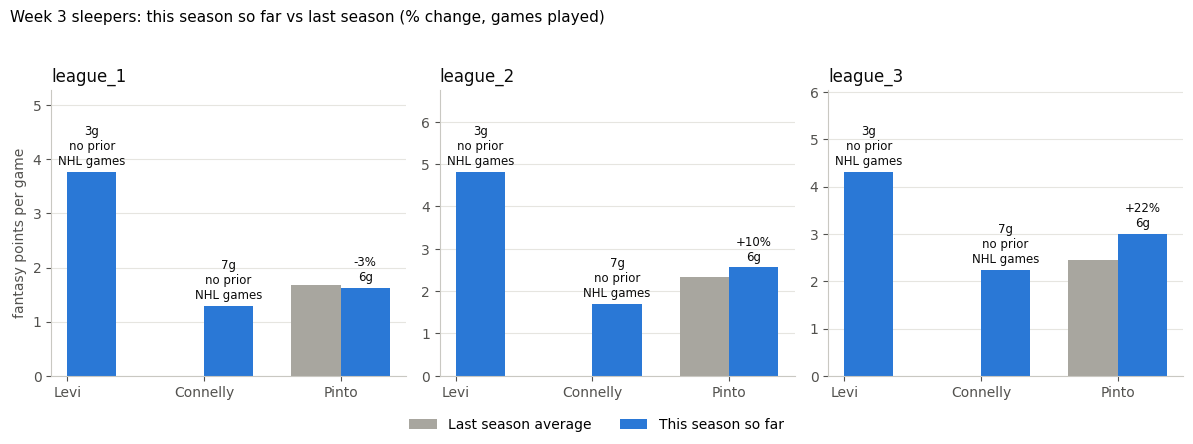

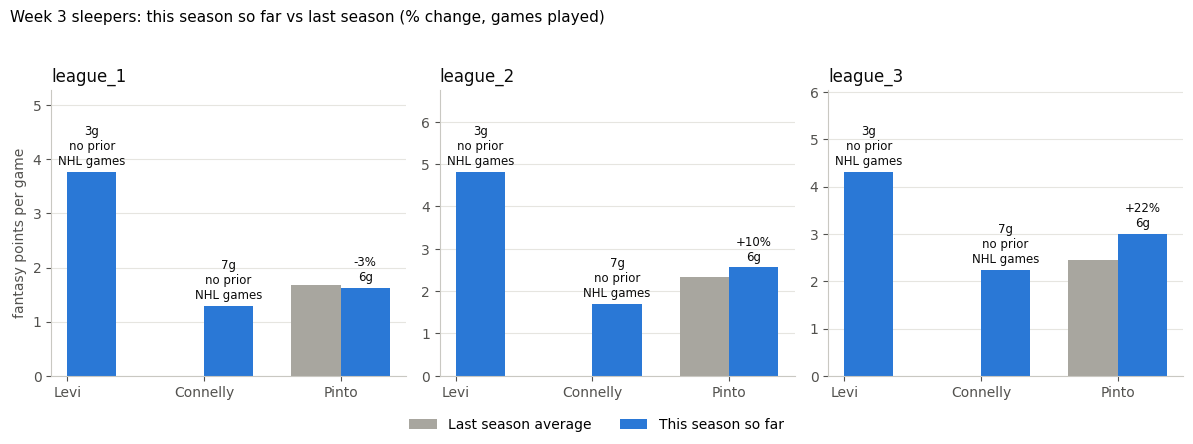

Loading game log for 8482221, 20262027 from cache, 0.0 hours old
Pulling fresh game log for 8482221, 20252026
No games found for 8482221 in 20252026, player likely wasn't in the NHL that season
Loading game log for 8484803, 20262027 from cache, 0.0 hours old
Pulling fresh game log for 8484803, 20252026
No games found for 8484803 in 20252026, player likely wasn't in the NHL that season
Loading game log for 8481596, 20262027 from cache, 0.0 hours old
Loading game log for 8481596, 20252026 from cache, 0.3 hours old


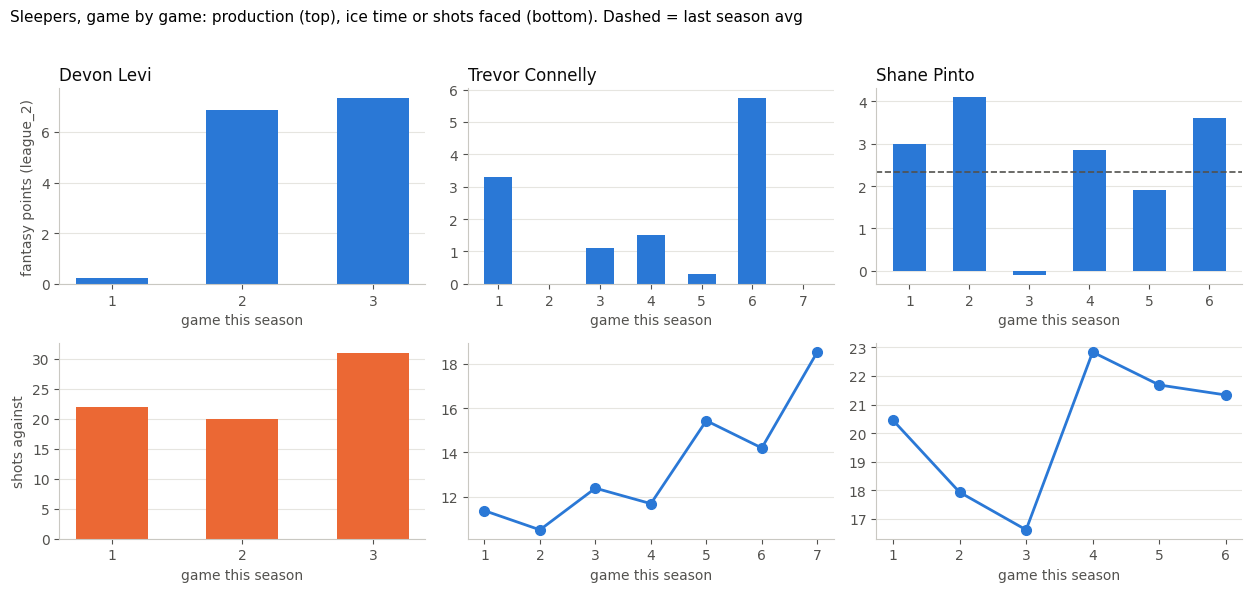

In [ ]:
def plot_sleepers_w3(df):
    leagues = sorted(df["league"].unique())
    players = list(dict.fromkeys(df["player"]))
    fig, axes = plt.subplots(1, len(leagues), figsize=(4.0 * len(leagues), 4.4))
    axes = np.atleast_1d(axes)
    x = np.arange(len(players)); w = 0.36
    for ax, league in zip(axes, leagues):
        d = df[df["league"] == league].set_index("player").loc[players]
        ax.bar(x - w/2, d["last_season_avg"], w, color=GRAY, label="Last season average")
        ax.bar(x + w/2, d["this_season_avg"], w, color=BLUE, label="This season so far")
        top = np.nanmax([d["last_season_avg"].max(), d["this_season_avg"].max()])
        for xi, (_, r) in zip(x, d.iterrows()):
            if pd.isna(r["this_season_avg"]):
                continue
            if pd.notna(r["vs_last_season"]):
                lab = f"{r['vs_last_season']:+.0%}\n{int(r['games'])}g"
            else:
                lab = f"{int(r['games'])}g\nno prior\nNHL games"
            ax.text(xi + w/2, r["this_season_avg"] + top * 0.02, lab,
                    ha="center", va="bottom", fontsize=8.5, color=INK)
        ax.set_ylim(0, top * 1.4)
        ax.set_xticks(x); ax.set_xticklabels([p.split()[-1] for p in players])
        ax.set_title(league, loc="left")
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("fantasy points per game")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=2, frameon=False)
    fig.suptitle("Week 3 sleepers: this season so far vs last season (% change, games played)",
                 x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0.06, 1, 0.95))
    plt.show()

plot_sleepers_w3(sleepers_w3)

plot_sleepers_w3(sleepers_w3)

def plot_sleeper_games_w3(league="league_2"):
    n = len(SLEEPERS_W3)
    fig, axes = plt.subplots(2, n, figsize=(4.2 * n, 6), squeeze=False)
    for j, name in enumerate(SLEEPERS_W3):
        pos = SLEEPER_POSITION.get(name, "F")
        cfg, fmap = cfg_and_map(league, pos)
        pid = resolve_id(name)
        cur = _scored_game_log(pid, SEASON, pos, cfg, fmap, force_refresh=False)
        last_avg = get_prior_season_stats(pid, PRIOR_SEASON, pos, cfg, fmap)[0]
        ax, ax2 = axes[0, j], axes[1, j]
        if cur is None or cur.empty:
            ax.set_title(f"{name}: no games yet", loc="left"); continue
        cur = cur.reset_index(drop=True)
        g = np.arange(1, len(cur) + 1)
        ax.bar(g, cur["fantasy_points"], color=BLUE, width=0.55)
        if last_avg: ax.axhline(last_avg, color=MUTED, linestyle="--", linewidth=1.2)
        ax.set_title(name, loc="left"); ax.set_xticks(g); ax.set_xlabel("game this season")
        if j == 0: ax.set_ylabel(f"fantasy points ({league})")
        ax.grid(axis="x", visible=False)
        if pos == "G" and "shotsAgainst" in cur.columns:
            ax2.bar(g, pd.to_numeric(cur["shotsAgainst"], errors="coerce"), color=ORANGE, width=0.55)
            ax2.set_ylabel("shots against") if j == 0 else None
        elif "toi" in cur.columns:
            ax2.plot(g, cur["toi"].map(toi_minutes), color=BLUE, linewidth=2, marker="o", markersize=7)
            ax2.set_ylabel("minutes on ice") if j == 0 else None
        ax2.set_xticks(g); ax2.set_xlabel("game this season"); ax2.grid(axis="x", visible=False)
    fig.suptitle("Sleepers, game by game: production (top), ice time or shots faced (bottom). Dashed = last season avg",
                 x=0.01, ha="left", fontsize=11)
    plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.show()

plot_sleeper_games_w3("league_2")

In [ ]:
SLEEPER_THESIS = {
    "Devon Levi": "Taking the starting job in Edmonton, at least for the next few months.",
    "Trevor Connelly": "Ice time has been climbing through his first 7 games, shooting about 2 times a game.",
    "Shane Pinto": "Playing more than last season (20.1 vs 18.7 minutes) without a hot shooting percentage behind it.",
}
sl_out = sleepers_w3.copy()
sl_out["week"] = 3
sl_out["thesis"] = sl_out["player"].map(SLEEPER_THESIS)
sl_out["window_start"], sl_out["window_end"] = WEEK3["league_1"]
sl_out.to_csv("predictions/sleepers_week03.csv", index=False)
pd.concat([sleepers_process_w3.assign(kind="skater"), sleepers_goalie_w3.assign(kind="goalie")], ignore_index=True) \
  .to_csv("predictions/sleepers_week03_process.csv", index=False)
print("Saved sleepers_week03.csv and sleepers_week03_process.csv")
try:
    from google.colab import files  # type: ignore
    files.download("predictions/sleepers_week03.csv")
    files.download("predictions/sleepers_week03_process.csv")
except ImportError:
    pass

Saved sleepers_week03.csv and sleepers_week03_process.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Week 3 sleepers

Chosen before the games, with a one-line thesis for each so next week's recap can check what I expected. Rostered % in brackets.

- **Devon Levi, G (35%).** Taking the starting job in Edmonton, at least for the next few months.
- **Trevor Connelly (13%).** His ice time has been climbing through his first 7 games, and he is taking about 2 shots a game.
- **Shane Pinto (22%).** He is playing more than last season (20.1 vs 18.7 minutes) without a hot shooting percentage behind it.

**What the data says going in** (real NHL stats, this season so far):

| Player | Games | Pts/g | Shots/g | Shooting % | TOI (min) |
|---|---|---|---|---|---|
| Connelly | 7 | 0.57 | 2.14 | 13% | 13.4 |
| Pinto | 6 | 0.83 | 1.67 | 10% | 20.1 |
| Pinto, last season | 72 | 0.64 | 2.18 | 15% | 18.7 |

| Goalie | Games | Starts | Team games | Start share | Wins | Sv% | GA/g |
|---|---|---|---|---|---|---|---|
| Levi | 3 | 3 | 5 | 0.60 | 3 | .860 | 3.33 |

Fantasy points per game this season, and against last season where there is a baseline:

| Player | Team | Games | League 1 | League 2 | League 3 |
|---|---|---|---|---|---|
| Levi | EDM | 3 | 3.77 | 4.82 | 4.31 |
| Connelly | VGK | 7 | 1.29 | 1.71 | 2.23 |
| Pinto | OTT | 6 | 1.62 (-3%) | 2.56 (+10%) | 3.01 (+22%) |

All three have 3 team games in the Week 3 window (Tue to Sun).

**How to read it:**
- **Levi and Connelly had no NHL games last season**, so there is no baseline and no percentage change. The model has only 3 and 7 games to go on, so treat their numbers as thin data.
- **Levi's model inputs are defaults.** With no prior games, the model uses a 0.50 start share (1.5 expected starts over Edmonton's 3 games). His actual share this season is 0.60 (3 of 5 starts), which would be 1.8. His three fantasy numbers (3.77, 4.82 and 4.31 per game) are just his 3-game average, with no prior to blend toward.
- **Levi's** 3 of 5 starts is a real share but not an exclusive one. His 3-0 record comes with a .860 save percentage, so his fantasy points are largely wins, which depend more on goal support than on how well he plays.
- **Connelly's** ice time has risen from about 10.5 to 18.5 minutes across his 7 games, while his production is uneven. A growing role with steady shot volume is the part of the thesis the data supports.
- **Pinto's** ice time is above last season's, while his shots and shooting percentage are both below it. His early production isn't a hot-shooting story. His fantasy points are running ahead of last season in leagues 2 and 3 (+10%, +22%) and slightly behind in league 1 (-3%).

**What I'll check next week:** whether Levi's start share holds (2 or more of his team's games) and his save percentage recovers, whether Connelly's ice time stays above 15 minutes, and whether Pinto's production stays above last season's. Three players and a few games each, so this tracks the method and doesn't prove anything about it.

## Week 3 analysis

**Late start.** Predictions made Tuesday Oct 13 after Monday's games, window is Oct 13-18 (Tue-Sun). Almost every team has 3 games in the window, so there is almost no schedule edge this week. The model's edge so far has come from game-count differences (Week 2: 10 of 13 on unequal games, 16 of 31 on equal), so I'd expect this week to land near a coin flip however confident the numbers look.

### Headline picks
1. **Tim Stutzle over Fraser Minten** (league 1), 85.0%. 3 games each. Season-level and recent-form numbers agree (72.5% per game, 91.2% on recent form). The 85% comes more from Minten's low expectation (3.9 vs 8.7 points) than from Stutzle being unbeatable. Stutzle is also in leagues 2 and 3 (81.6%, 69.5%), so those are one player's week counted three times, not three independent bets.
2. **Sebastian Aho over Brayden Point** (league 2), 81.2%. 9.8 vs 5.4 expected points; per-game 69.5%, recent form 94.2%.
3. **Mikhail Sergachev over Mackenzie Weegar** (league 3), 77.7%. 10.9 vs 5.7 expected points; per-game 67.0%, recent form 80.9%.

Not chosen: Charlie McAvoy over Mattias Ekholm (league 2, 84.9%) is the highest number in league 2, but McAvoy has played 0 games this season, so it rests on last season alone.

### Close calls
Nelson vs Larkin (49.2%, league 3), Blackwood vs Silovs (48.6%, league 2), Andersson vs Dobson (48.2%, league 3) and Dobes vs Bussi (46.5%, league 3): the model sees no difference. These are coin flips, not leans.

### Likely to be outperformed
- Harley vs Bouchard (league 3), 10.9% that I win: 5.4 vs 16.3 expected points, and the distributions barely overlap. The most lopsided call against me.
- Miller vs Draisaitl (league 3), 18.9%: 9.5 vs 17.0.
- Ovechkin vs Aho (league 3), 20.9%: 7.9 vs 14.0.
- LaCombe vs Gostisbehere (league 2), 29.3%: a game-count gap, 2 vs 3 games, which turns a 53.8% per-game number into 29.3% for the week.

### Goalie call
**Swayman over Dostal** (league 1), 70%. Swayman has 3 team games to Dostal's 2, with similar start shares (.66 vs .67), so this is a schedule edge and not a judgment about who plays better.

Oettinger vs Wallstedt (league 2, 66%) depends on a start-share assumption: Oettinger .66 vs Wallstedt .40 (last season's starts). Re-running with Wallstedt at 0.60 gives 55.7%, and at 0.70 it's a coin flip (50.5%). Wallstedt played all 3 of his team's games last week, so .40 may be stale. No override applied; this week's result will show whether the start-share rule needs adjusting.

### Things to watch
- Bedard (league 1) and McAvoy (league 2) have 0 games this season, so those slots rest on last season alone.
- The model assumes every player plays every team game. Last week Demidov (0 of 3), Marchand (1 of 2) and Dobes (1 of 3) missed games.
- Where season and recent-form numbers disagree most: Samuelsson vs Slavin (71.4% vs 40.9%), Dobson vs Gavrikov (44.5% vs 23.0%), Andersson vs Dobson (48.2% vs 70.5%).